# 08 · Fase 4: matriz de efectos entre categorías

Construye la **matriz de efectos entre categorías** a partir de los resultados de la fase 2 (`07_fase2`). No estima ningún modelo: lee la tabla `fase2_efectos_cruzados.csv` y la dibuja.

Filas: categoría afectada $j$. Columnas: categoría en promoción $k$. Cada celda es el efecto, en %, de **+10 pp del surtido de $k$ en promoción** sobre las ventas de $j$:

- **día** ($L_{jk}$): el día de la promoción. Es la lectura principal.
- **neto** ($L^{\text{net}}_{jk}$): +10 pp sostenidos 7 días. Es complementaria y descansa en rezagos muy colineales en las categorías con campañas de varios días.

| | |
|---|---|
| **Entrada** | `resultados/tablas/fase2_efectos_cruzados.csv` (la deja `07_fase2`) |
| **Tablas** | `fase4_matriz_Ljk_dia_pct.csv`, `fase4_matriz_Ljk_neto_pct.csv` |
| **Figuras** | `fase4_matriz_efectos_cruzados_dia.png`, `fase4_matriz_efectos_cruzados_neto.png` |

**Orden de ejecución:** `07_fase2` primero, después este notebook.

## Paso 1. Librerías y parámetros

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap

# D-28 y D-30: categorías objetivo; primero las sin programa, luego las con programa (D-26)
categorias = [
    "BEVERAGES", "GROCERY I", "CLEANING", "DAIRY", "BREAD/BAKERY", "LIQUOR,WINE,BEER",
    "MEATS", "POULTRY", "DELI", "PRODUCE",
]
categorias_programa = ["MEATS", "POULTRY", "DELI", "PRODUCE"]
delta_p = 0.10   # los efectos son de +10 puntos porcentuales del surtido de k en promoción

ruta_tablas = os.path.join("resultados", "tablas")
ruta_figuras = os.path.join("resultados", "figuras")
os.makedirs(ruta_tablas, exist_ok=True)
os.makedirs(ruta_figuras, exist_ok=True)

## Paso 2. Importar los efectos entre categorías

La tabla trae una fila por par $(j,k)$ con el efecto del día y el neto, su significancia corregida (Benjamini‑Hochberg, D‑15) y el rango p10‑p90 de $k$. Con ese rango se marca `fuera_de_soporte` (†): +10 pp supera la variación habitual de $k$ y el efecto es una extrapolación.

In [2]:
efectos_cruzados = pd.read_csv(os.path.join(ruta_tablas, "fase2_efectos_cruzados.csv"))
assert len(efectos_cruzados) == len(categorias) * (len(categorias) - 1), "faltan pares (j, k)"

# Rango p10-p90 de cada categoría k (una sola cifra por categoría, repetida en cada fila de la tabla)
rango_p10_p90 = efectos_cruzados.groupby("categoria_en_promocion_k")["rango_p10_p90_k"].first().reindex(categorias)
assert rango_p10_p90.notna().all(), "falta el rango de alguna categoría"
print(efectos_cruzados[["categoria_afectada_j", "categoria_en_promocion_k", "dia_efecto_pct", "dia_p_bh", "dia_significativo"]].head())
print(f"\nPares significativos tras Benjamini-Hochberg: día {int(efectos_cruzados['dia_significativo'].sum())}, neto {int(efectos_cruzados['neto_significativo'].sum())}")

  categoria_afectada_j categoria_en_promocion_k  dia_efecto_pct  dia_p_bh  \
0            BEVERAGES             BREAD/BAKERY       -8.962027  0.074720   
1            BEVERAGES                 CLEANING       -8.856906  0.153207   
2            BEVERAGES                    DAIRY        3.504128  0.497829   
3            BEVERAGES                     DELI       -2.511581  0.236799   
4            BEVERAGES                GROCERY I        5.017504  0.538347   

   dia_significativo  
0              False  
1              False  
2              False  
3              False  
4              False  

Pares significativos tras Benjamini-Hochberg: día 0, neto 7


## Paso 3. Matriz de efectos entre categorías

Filas: categoría afectada $j$. Columnas: categoría en promoción $k$. Celdas: efecto en % de +10 pp del surtido de $k$ en promoción, el día de la promoción ($L_{jk}$) y sostenido 7 días ($L^{\text{net}}_{jk}$). Las celdas con borde y asterisco son significativas tras Benjamini‑Hochberg; † indica que +10 pp está fuera del rango habitual de $k$; ‡ indica categorías con programa (promociones fuera del programa).

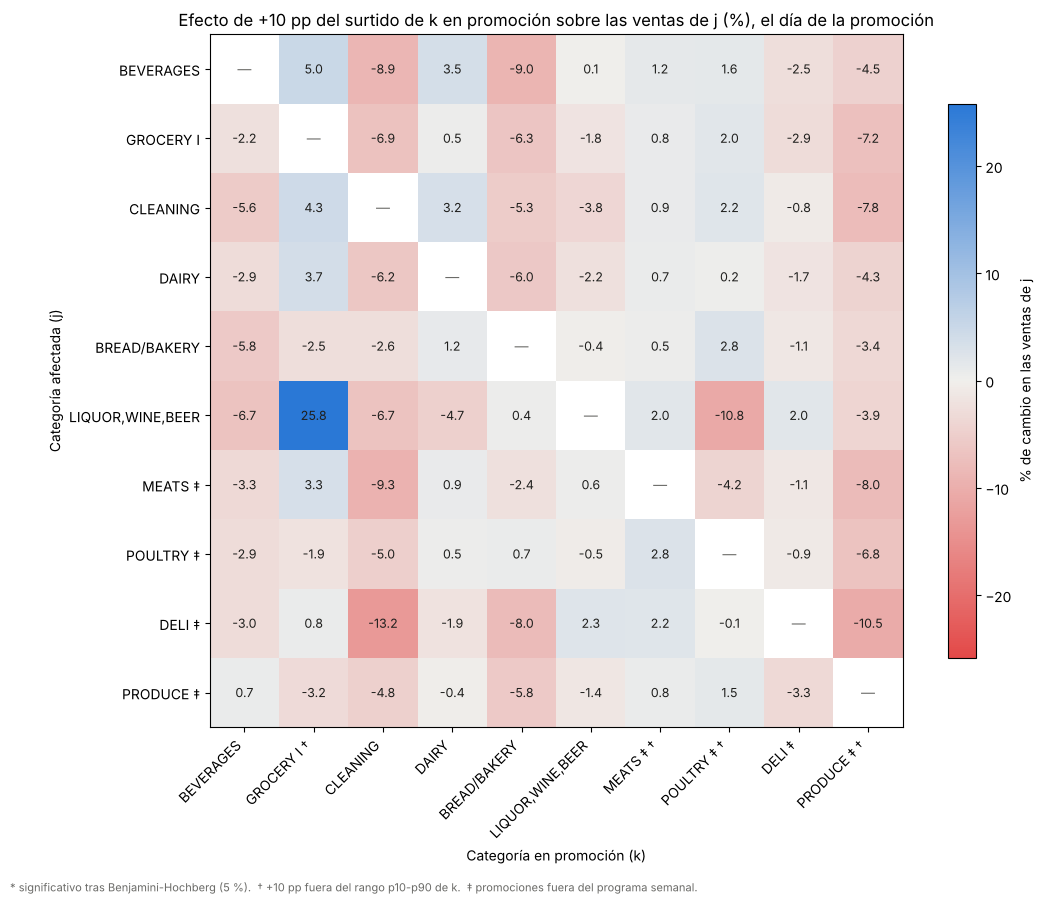

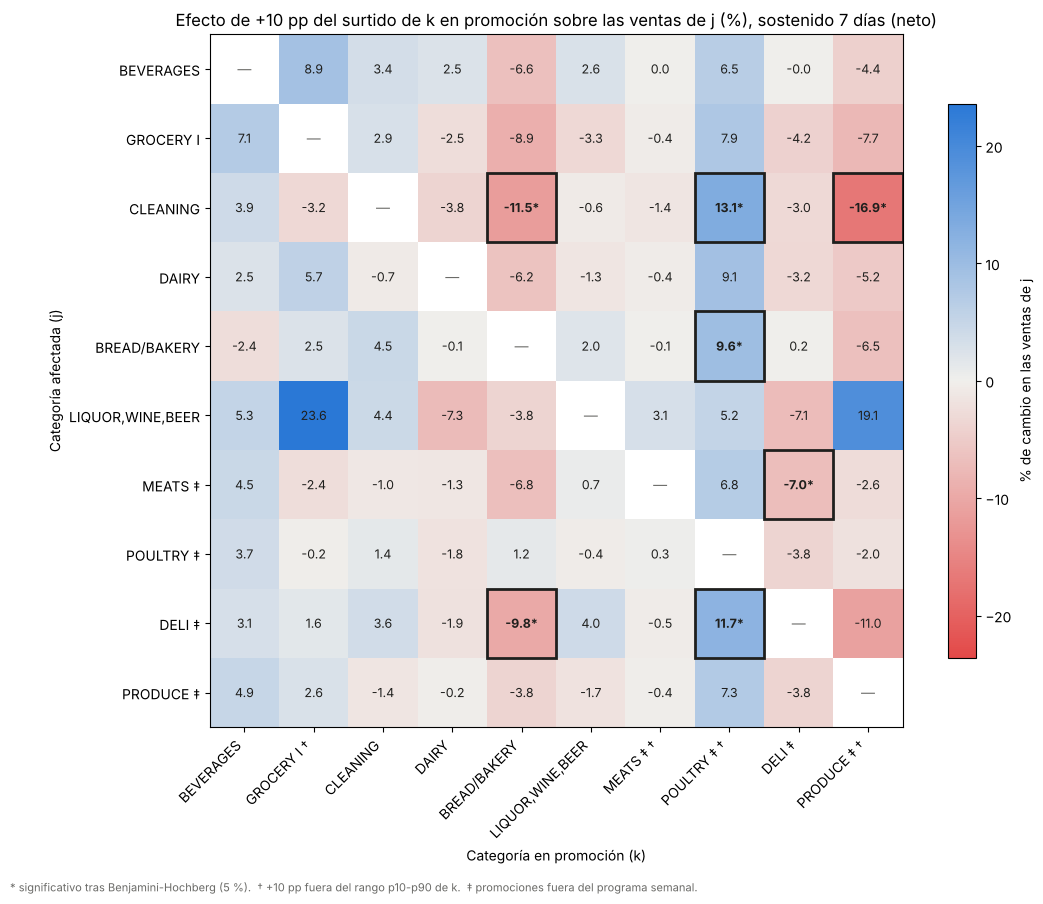

In [3]:
# Escala divergente: rojo = canibalización, gris = sin efecto, azul = sinergia
escala = LinearSegmentedColormap.from_list("divergente", ["#e34948", "#f0efec", "#2a78d6"])
etiquetas = [f"{c} ‡" if c in categorias_programa else c for c in categorias]
etiquetas_k = [f"{e} †" if rango_p10_p90[c] < delta_p else e for e, c in zip(etiquetas, categorias)]
matrices = {}

for bloque, titulo in [("dia", "el día de la promoción"), ("neto", "sostenido 7 días (neto)")]:
    matriz, significancia = [
        efectos_cruzados.pivot(index="categoria_afectada_j", columns="categoria_en_promocion_k", values=v)
        .reindex(index=categorias, columns=categorias)
        for v in [f"{bloque}_efecto_pct", f"{bloque}_significativo"]
    ]
    matrices[bloque] = matriz
    limite = np.nanmax(np.abs(matriz.to_numpy(dtype=float)))

    figura, eje = plt.subplots(figsize=(11, 9))
    imagen = eje.imshow(matriz.to_numpy(dtype=float), cmap=escala, vmin=-limite, vmax=limite)
    for i, j in np.ndindex(matriz.shape):
        if i == j:
            eje.text(j, i, "—", ha="center", va="center", color="#6b6b68")
            continue
        marca = "*" if significancia.iat[i, j] else ""
        eje.text(j, i, f"{matriz.iat[i, j]:.1f}{marca}", ha="center", va="center", fontsize=9,
                 fontweight="bold" if marca else "normal", color="#1f1f1d")
        if marca:
            eje.add_patch(plt.Rectangle((j - 0.5, i - 0.5), 1, 1, fill=False, edgecolor="#1f1f1d", linewidth=2))
    eje.set_xticks(range(len(categorias)), etiquetas_k, rotation=45, ha="right")
    eje.set_yticks(range(len(categorias)), etiquetas)
    eje.set_xlabel("Categoría en promoción (k)")
    eje.set_ylabel("Categoría afectada (j)")
    eje.set_title(f"Efecto de +10 pp del surtido de k en promoción sobre las ventas de j (%), {titulo}")
    figura.colorbar(imagen, ax=eje, shrink=0.8, label="% de cambio en las ventas de j")
    figura.text(0.01, 0.01, "* significativo tras Benjamini-Hochberg (5 %).  † +10 pp fuera del rango p10-p90 de k.  "
                "‡ promociones fuera del programa semanal.", fontsize=8, color="#6b6b68")
    figura.tight_layout(rect=(0, 0.03, 1, 1))
    figura.savefig(os.path.join(ruta_figuras, f"fase4_matriz_efectos_cruzados_{bloque}.png"), dpi=300)
    plt.show()

## Paso 4. Exportación

In [4]:
for bloque in ["dia", "neto"]:
    matrices[bloque].to_csv(os.path.join(ruta_tablas, f"fase4_matriz_Ljk_{bloque}_pct.csv"))

print(f"Guardado: 2 matrices en {ruta_tablas} y 2 figuras en {ruta_figuras}")
print(">>>> Proceso finalizado <<<<")

Guardado: 2 matrices en resultados/tablas y 2 figuras en resultados/figuras
>>>> Proceso finalizado <<<<
